In [1]:
from matplotlib import pyplot as plt
from matplotlib.patches import ConnectionPatch
import seaborn as sns

from scipy.stats import ttest_1samp, bootstrap
from scipy.interpolate import interp1d
import numpy as np
import pandas as pd
import polars as pl
import os

from pymer4.models import glmer

from bids import BIDSLayout
layout = BIDSLayout('bids_dataset', derivatives = True)

# Behavioral Data

In [2]:
# select subjects with acceptable EEG impedances
participants = layout.get(suffix = 'participants', extension = 'tsv')[0].get_df()
high_imp = participants.notes.str.contains('exceeded') == True
sub_nums = participants.participant_id.str.extract(r'sub-(\w+)')
good_subs = sub_nums[~high_imp].iloc[:, 0].to_list()
print('Excluded', sub_nums[high_imp][0].to_list())
print('%d subjects remaining.'%len(good_subs))

fs = layout.get(subject = good_subs, task = 'streaming', suffix = 'events', extension = 'tsv')
events = [f.get_df() for f in fs]
for ev, f in zip(events, fs):
    ev.insert(0, 'subject', f.entities['subject']) 
events = pd.concat(events)
trials = events[events.tone_num == 1] # so we don't over count trials b/c multiple tones
trials = trials.reset_index(drop = True)
trials['response'] = trials.response == 'streaming'
trials.head()

Excluded ['08', '19']
20 subjects remaining.


,subject,onset,duration,trial_num,trial_type,tone_num,tone_type,frequency,response
0,01,190.3276,0.132501,1,systole,1,A,1578.567003,False
1,01,208.5275,0.118755,2,diastole,1,A,1578.567003,False
2,01,221.4114,0.117513,3,systole,1,A,2180.022500,False
3,01,236.8508,0.123097,4,diastole,1,A,2180.022500,False
4,01,254.5302,0.138158,5,diastole,1,A,1987.945240,False


In [3]:
mod = glmer(
    'response ~ trial_type + (1 | subject)', 
    data = pl.DataFrame(trials),
    family = 'binomial', link = 'logit'
)
mod.set_factors('trial_type')
mod.fit(summary = True, conf_level = .95)

GT(_tbl_data=shape: (5, 10)
┌────────────────┬────────────────┬───────────┬───────────┬───┬───────────┬──────┬─────────┬───────┐
│ rfx            ┆ param          ┆ estimate  ┆ conf_low  ┆ … ┆ z_stat    ┆ df   ┆ p_value ┆ stars │
│ ---            ┆ ---            ┆ ---       ┆ ---       ┆   ┆ ---       ┆ ---  ┆ ---     ┆ ---   │
│ str            ┆ str            ┆ f64       ┆ f64       ┆   ┆ f64       ┆ f64  ┆ str     ┆ str   │
╞════════════════╪════════════════╪═══════════╪═══════════╪═══╪═══════════╪══════╪═════════╪═══════╡
│ subject-sd     ┆ (Intercept)    ┆ 0.483438  ┆ null      ┆ … ┆ null      ┆ null ┆ null    ┆ null  │
│ null           ┆ null           ┆ null      ┆ null      ┆ … ┆ null      ┆ null ┆ null    ┆ null  │
│ Fixed Effects: ┆ null           ┆ null      ┆ null      ┆ … ┆ null      ┆ null ┆ null    ┆ null  │
│ null           ┆ (Intercept)    ┆ -0.311689 ┆ -0.560048 ┆ … ┆ -2.459749 ┆ inf  ┆ 0.0139  ┆ *     │
│ null           ┆ trial_typesyst ┆ 0.189255  ┆ 0.006903  ┆ … ┆ 2.03416   ┆ inf  ┆ 0.04194 ┆ *     │
│                ┆ ole            ┆           ┆           ┆   ┆           ┆      ┆         ┆       │
└────────────────┴────────────────┴───────────┴───────────┴───┴───────────┴──────┴─────────┴───────┘, _body=<great_tables._gt_data.Body object at 0x7f932a238770>, _boxhead=Boxhead([ColInfo(var='rfx', type=<ColInfoTypeEnum.default: 1>, column_label='Random Effects:', column_align='left', column_width=None), ColInfo(var='param', type=<ColInfoTypeEnum.default: 1>, column_label='', column_align='left', column_width=None), ColInfo(var='estimate', type=<ColInfoTypeEnum.default: 1>, column_label='Estimate', column_align='right', column_width=None), ColInfo(var='conf_low', type=<ColInfoTypeEnum.default: 1>, column_label='CI-low', column_align='right', column_width=None), ColInfo(var='conf_high', type=<ColInfoTypeEnum.default: 1>, column_label='CI-high', column_align='right', column_width=None), ColInfo(var='std_error', type=<ColInfoTypeEnum.default: 1>, column_label='SE', column_align='right', column_width=None), ColInfo(var='z_stat', type=<ColInfoTypeEnum.default: 1>, column_label='Z-stat', column_align='right', column_width=None), ColInfo(var='df', type=<ColInfoTypeEnum.default: 1>, column_label='df', column_align='right', column_width=None), ColInfo(var='p_value', type=<ColInfoTypeEnum.default: 1>, column_label='p', column_align='left', column_width=None), ColInfo(var='stars', type=<ColInfoTypeEnum.default: 1>, column_label='', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x7f932a23a870>, _spanners=Spanners([]), _heading=Heading(title='Formula: glmer(response~trial_type+(1|subject))', subtitle=Md(text='Family: *binomial (link: *logit*)*  \n            Number of observations: *1975*  \n            Confidence intervals: *parametric*  \n            ---------------------  \n            Log-likelihood: *-1322*  \n            AIC: *2650* | BIC: *2667*  \n            Residual error: *1.0*  \n        '), preheader=None), _stubhead=None, _source_notes=[Md(text='Signif. codes: *0 *** 0.001 ** 0.01 * 0.05 . 0.1*')], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=['param'], rows=None, mask=None), grpname=None, colname='param', rownum=0, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style='italic', weight=None, stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns=['param'], rows=None, mask=None), grpname=None, colname='param', rownum=1, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style='italic', weight=None, stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns=['param'], rows=None, mask=None), grpname=None, colname='param', rownum=2, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style='italic', weight=None, stretch=None, decorate=None, tra

In [4]:
def calc_boot_mean_CIs(x, conf_level = .95):
    '''
    finds smallest intervals containing conf_level proportion
    of the bootstrap samples (i.e. highest density interval)
    '''
    import arviz as az
    try: # deal with multiple arviz versions
        ci = az.hdi(x, prob = conf_level)
    except:
        ci = az.hdi(x, hdi_prob = conf_level)
    return ci

def get_marginal_CIs(mod, conf_level = .95):
    sigmoid = lambda x: 1 / (1 + np.exp(-x))
    diastole_boot = sigmoid(mod.result_boots['(Intercept)']).to_numpy()
    systole_boot = sigmoid(mod.result_boots['(Intercept)'] + mod.result_boots['trial_typesystole']).to_numpy()
    delta_boot = systole_boot - diastole_boot
    res = dict(
        diastole = dict(
            samples = diastole_boot,
            mean = diastole_boot.mean(),
            ci = calc_boot_mean_CIs(diastole_boot, conf_level)
        ),
        systole = dict(
            samples = systole_boot,
            mean = systole_boot.mean(),
            ci = calc_boot_mean_CIs(systole_boot, conf_level)
        ),
        delta = dict(
            samples = delta_boot,
            mean = delta_boot.mean(),
            ci = calc_boot_mean_CIs(delta_boot, conf_level)
        )
    )
    return res

# `seed` argument not described in pymer4 docs, but passed to R's bootMer regardless
mod.fit(summary = False, conf_method = 'boot', nboot = 10000, seed = 0)
res = get_marginal_CIs(mod, conf_level = .95)
for ci in ['diastole', 'systole', 'delta']:
    _res = res[ci]
    print('Bootstrap marginal mean for %s on probability scale:'%ci, _res['mean'], _res['ci'])

R messages: 
In addition: 
Warning messages:

1: 
In hatvalues.merMod(model) :

 
 the hat matrix may not make sense for GLMMs

2: 
In hatvalues.merMod(model) :

 
 the hat matrix may not make sense for GLMMs

3: 
In hatvalues.merMod(model) :

 
 the hat matrix may not make sense for GLMMs

4: 
In hatvalues.merMod(model) :

 
 the hat matrix may not make sense for GLMMs

5: 
In hatvalues.merMod(model) :

 
 the hat matrix may not make sense for GLMMs

6: 
In hatvalues.merMod(model) :

 
 the hat matrix may not make sense for GLMMs

R messages: 
In addition: 
Warning messages:

1: 
In hatvalues.merMod(model) :

 
 the hat matrix may not make sense for GLMMs

2: 
In hatvalues.merMod(model) :

 
 the hat matrix may not make sense for GLMMs

3: 
In hatvalues.merMod(model) :

 
 the hat matrix may not make sense for GLMMs

4: 
In hatvalues.merMod(model) :

 
 the hat matrix may not make sense for GLMMs

5: 
In hatvalues.merMod(model) :

 
 the hat matrix may not make sense for GLMMs

6: 
In

# EEG Data

In [5]:
df = pd.concat([f.get_df() for f in layout.get(subject = good_subs, desc = '500Hz')])
systole = df.amplitude[df.condition == 'systole'].to_numpy()
diastole = df.amplitude[df.condition == 'diastole'].to_numpy()
ttest_1samp(systole - diastole, popmean = 0)

TtestResult(statistic=np.float64(-2.109991745326186), pvalue=np.float64(0.048347232566909745), df=np.int64(19))

In [6]:
boot = bootstrap([systole], np.mean, confidence_level = 0.95, n_resamples = 10000, random_state = 0)
boot.bootstrap_distribution.mean(), calc_boot_mean_CIs(boot.bootstrap_distribution, .95)

(np.float64(12.953297436243481), array([10.71693447, 15.12428735]))

In [7]:
boot = bootstrap([diastole], np.mean, confidence_level = 0.95, n_resamples = 10000, random_state = 0)
boot.bootstrap_distribution.mean(), calc_boot_mean_CIs(boot.bootstrap_distribution, .95)

(np.float64(13.941867947386264), array([11.6053177, 16.1094772]))

In [8]:
boot = bootstrap([systole - diastole], np.mean, confidence_level = 0.95, n_resamples = 10000, random_state = 0)
boot.bootstrap_distribution.mean(), calc_boot_mean_CIs(boot.bootstrap_distribution, .95)

(np.float64(-0.9885705111427833), array([-1.9068336, -0.1080099]))

# Figure

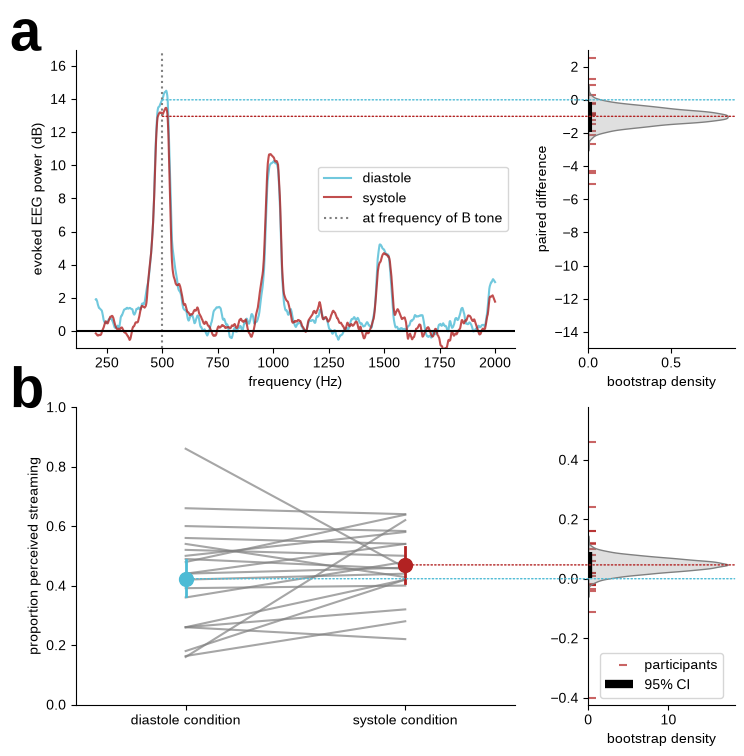

In [9]:
fig, axs = plt.subplots(2, 2, width_ratios = (3, 1), gridspec_kw = dict(wspace = .25), figsize = (8.5, 8.5))
syst = trials[trials.trial_type == 'systole'].groupby('subject')['response'].mean().to_numpy()
diast = trials[trials.trial_type == 'diastole'].groupby('subject')['response'].mean().to_numpy()
delta = syst - diast

syst_col = 'firebrick'
diast_col = '#4DBBD5FF'

################# EEG data

# frequencies for which to plot power
freqs = np.linspace(200, 2000, 2000-200)

def get_sub_power(sub, cond):
    '''
    interpolates power (dB) at common frequency values for all subjects
    (because the exact frequencies at which power was computed for each
    participant depended on the epoch duration, which depended on the 
    stimulus length, which depended on their individual heart rate!)
    '''
    pow_df = layout.get(subject = sub, desc = cond, suffix = 'power')[0].get_df()
    f = interp1d(pow_df.freq, pow_df.dB, fill_value = 'extrapolate')
    dB = f(freqs)
    return dB

subs = good_subs
dB_systole = np.stack([get_sub_power(sub, 'systole') for sub in subs]).mean(0)
dB_syst_std = 1.96*np.stack([get_sub_power(sub, 'systole') for sub in subs]).std(0)
dB_diastole = np.stack([get_sub_power(sub, 'diastole') for sub in subs]).mean(0)
dB_dias_std = 1.96*np.stack([get_sub_power(sub, 'diastole') for sub in subs]).std(0)
axs[0, 0].plot(freqs, dB_diastole, label = 'diastole', color = diast_col, alpha = .8)
axs[0, 0].plot(freqs, dB_systole, label = 'systole', color = syst_col, alpha = .8)
axs[0, 0].set_xlabel('frequency (Hz)')
axs[0, 0].set_ylabel('evoked EEG power (dB)')
axs[0, 0].axvline(500, linestyle = 'dotted', color = 'gray', label = 'at frequency of B tone')
axs[0, 0].legend(loc = 'center right')
axs[0, 0].axhline(0, color = 'black')
axs[0, 0].set_ylim(-1, diastole.mean() + 3)
axs[0, 0].spines[['top', 'right']].set_visible(False)

sns.kdeplot(y = boot.bootstrap_distribution, color = 'grey', fill = True, ax = axs[0, 1])
axs[0, 1].set_xlabel('bootstrap density')
axs[0, 1].set_ylabel('paired difference')
axs[0, 1].set_ylim(-1 - diastole.mean(), 3)
axs[0, 1].scatter(np.zeros_like(systole), systole-diastole, marker = 1, zorder = 0, color = syst_col, alpha = .7, label = 'participants')
axs[0, 1].vlines(.0075, boot.confidence_interval[0], boot.confidence_interval[1], color = 'black', label = '95% CI')
axs[0, 1].vlines(.015, boot.confidence_interval[0], boot.confidence_interval[1], color = 'black')
axs[0, 1].spines[['top', 'right']].set_visible(False)

################ behavioral data

x_pos = [-.25, 1.25]
for s, d in zip(syst, diast):
    axs[1, 0].plot(x_pos, [d, s], color = 'gray', alpha = .7)
axs[1, 0].set_xlim(-1, 2)
axs[1, 0].set_ylim(0, 1)
axs[1, 0].set_xticks(x_pos, ['diastole condition', 'systole condition'])
axs[1, 0].scatter([x_pos[0]], res['diastole']['mean'], color = diast_col, s = 100, zorder = 10000)
axs[1, 0].plot(
    [x_pos[0], x_pos[0]], 
    [res['diastole']['ci'][0], res['diastole']['ci'][1]], 
    color = diast_col, linewidth = 2
)
axs[1, 0].scatter([x_pos[1]], res['systole']['mean'], color = syst_col, s = 100, zorder = 10000)
axs[1, 0].plot(
    [x_pos[1], x_pos[1]], 
    [res['systole']['ci'][0], res['systole']['ci'][1]], 
    color = syst_col, linewidth = 2
)
axs[1, 0].spines[['top', 'right']].set_visible(False)
axs[1, 0].set_ylabel('proportion perceived streaming')

ylim = axs[1, 0].get_ylim()
axs[1, 1].set_ylim(ylim[0] - res['diastole']['mean'], ylim[1] - res['diastole']['mean'])
axs[1, 1].set_xlabel('bootstrap density')
#axs[1, 1].set_ylabel('paired difference', zorder = 1000)
axs[1, 1].spines[['top', 'right']].set_visible(False)
sns.kdeplot(y = res['delta']['samples'], color = 'grey', fill = True, ax = axs[1, 1])
axs[1, 1].scatter(np.zeros_like(syst), syst-diast, marker = 1, zorder = 0, color = syst_col, alpha = .7, label = 'participants')
axs[1, 1].vlines(.0075, res['delta']['ci'][0], res['delta']['ci'][1], color = 'black', label = '95% CI', linewidth = 6)
axs[1, 1].legend(loc = 'lower center')
axs[1, 1].set_xlim(0, None)

################ Connecting lines

xlim = axs[0, 1].get_xlim()
con = ConnectionPatch(
    xyA = (500, diastole.mean()), 
    xyB = (xlim[1], 0),      
    coordsA = 'data',       
    coordsB = 'data',       
    axesA = axs[0, 0],    
    axesB = axs[0, 1], 
    linestyle = 'dotted',
    color = diast_col,
    zorder = 1000
)
fig.add_artist(con)
con = ConnectionPatch(
    xyA = (500, systole.mean()), 
    xyB = (xlim[1], (systole - diastole).mean()),      
    coordsA = 'data',       
    coordsB = 'data',       
    axesA = axs[0, 0],    
    axesB = axs[0, 1], 
    linestyle = 'dotted',
    color = syst_col,
    zorder = 1000
)
fig.add_artist(con)


xlim = axs[1, 1].get_xlim()
con = ConnectionPatch(
    xyA = (x_pos[0], res['diastole']['mean']), 
    xyB = (xlim[1], 0),      
    coordsA = 'data',       
    coordsB = 'data',       
    axesA = axs[1, 0],    
    axesB = axs[1, 1], 
    linestyle = 'dotted',
    color = diast_col,
    zorder = 1000
)
fig.add_artist(con)
con = ConnectionPatch(
    xyA = (x_pos[1], res['systole']['mean']), 
    xyB = (xlim[1], res['delta']['mean']),      
    coordsA = 'data',       
    coordsB = 'data',       
    axesA = axs[1, 0],    
    axesB = axs[1, 1], 
    linestyle = 'dotted',
    color = syst_col,
    zorder = 1000
)
fig.add_artist(con)

########### add panel labels 
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Liberation Sans'] + plt.rcParams['font.sans-serif']

def add_label(ax, label, x_offset = -.15, y_offset = .0):
    xmin, xmax = ax.get_xlim()
    xscale = xmax - xmin
    ymin, ymax = ax.get_ylim()
    yscale = ymax - ymin
    ax.text(
        xmin + x_offset*xscale, ymax + yscale*y_offset, 
        label, size = 40, weight = 'bold'
    )

add_label(axs[0, 0], 'a')
add_label(axs[1, 0], 'b')

plt.savefig('results.tif', dpi = 300, bbox_inches = 'tight')
plt.show()

This seems to be the simplest way of keeping track of the R package versions hidden behind the `pymer4` interface:

In [10]:
!conda list

# packages in environment at /home/johnv/miniforge3/envs/ecg-streaming2:
#
# Name                    Version                   Build  Channel
_openmp_mutex             4.5                  7_kmp_llvm    conda-forge
_python_abi3_support      1.0                  hd8ed1ab_2    conda-forge
_r-mutex                  1.0.1               anacondar_1    conda-forge
acres                     0.5.0                    pypi_0    pypi
adwaita-icon-theme        49.0                     unix_0    conda-forge
aiohappyeyeballs          2.7.1              pyhd8ed1ab_0    conda-forge
aiohttp                   3.14.1          py312h5d8c7f2_0    conda-forge
aiosignal                 1.4.0              pyhd8ed1ab_0    conda-forge
alsa-lib                  1.2.16.1             hb03c661_0    conda-forge
annotated-doc             0.0.4              pyhcf101f3_0    conda-forge
anyio                     4.14.1             pyhcf101f3_0    conda-forge
aom                       3.14.1          pl5321h039972f_1    